In [1]:

import pandas as pd

df = pd.read_excel('/content/Online Retail.xlsx')

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Information:")
df.info()


Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows:
5268

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [3]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows with missing CustomerID
df_clean = df_clean.dropna(subset=['CustomerID'])

# Remove rows with missing Description
df_clean = df_clean.dropna(subset=['Description'])

# Check the cleaned dataset
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(df_clean.duplicated().sum())


Original Dataset Shape: (541909, 8)
Cleaned Dataset Shape: (401604, 8)

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicate Rows After Cleaning:
0


In [4]:

# Calculate total amount for each transaction row
df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Display first 5 rows
df_clean[['CustomerID', 'InvoiceNo', 'Quantity',
          'UnitPrice', 'TotalAmount']].head()


,CustomerID,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,17850.0,536365,6,2.55,15.30
1,17850.0,536365,6,3.39,20.34
2,17850.0,536365,8,2.75,22.00
3,17850.0,536365,6,3.39,20.34
4,17850.0,536365,6,3.39,20.34


In [5]:

# Set the reference date as one day after the last transaction
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

# Display first 5 customers
rfm.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,2,0.00
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [6]:

# Check RFM values
print("Total Customers:", len(rfm))

print("\nNegative Monetary values:",
      (rfm['Monetary'] < 0).sum())

print("Zero Monetary values:",
      (rfm['Monetary'] == 0).sum())

print("Zero Frequency values:",
      (rfm['Frequency'] == 0).sum())

print("\nRFM Summary:")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())


Total Customers: 4372

Negative Monetary values: 42
Zero Monetary values: 8
Zero Frequency values: 0

RFM Summary:
           Recency    Frequency       Monetary
count  4372.000000  4372.000000    4372.000000
mean     92.047118     5.075480    1893.531433
std     100.765435     9.338754    8218.696204
min       1.000000     1.000000   -4287.630000
25%      17.000000     1.000000     291.795000
50%      50.000000     3.000000     644.070000
75%     143.000000     5.000000    1608.335000
max     374.000000   248.000000  279489.020000


In [7]:

from sklearn.preprocessing import StandardScaler

# Keep customers with positive total spending
rfm_model = rfm[rfm['Monetary'] > 0].copy()

print("Customers before filtering:", len(rfm))
print("Customers used for clustering:", len(rfm_model))
print("Customers excluded:", len(rfm) - len(rfm_model))

# Select RFM features
features = ['Recency', 'Frequency', 'Monetary']

# Scale the data
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_model[features])

print("\nScaled data shape:", rfm_scaled.shape)


Customers before filtering: 4372
Customers used for clustering: 4322
Customers excluded: 50

Scaled data shape: (4322, 3)


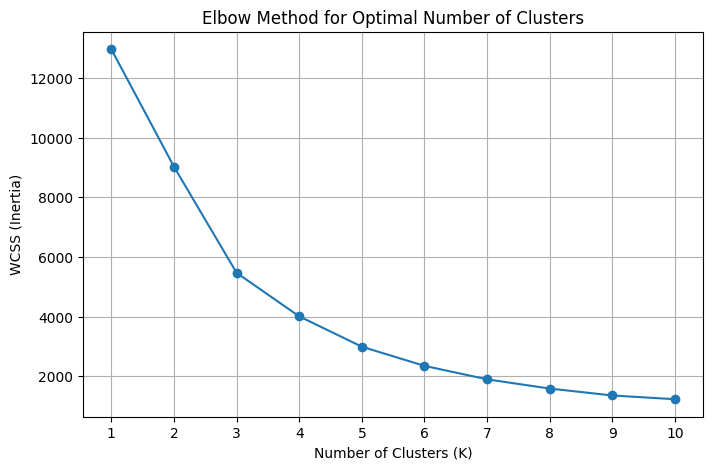

In [8]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate WCSS for different cluster counts
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [9]:

# Apply K-Means clustering with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm_model['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display cluster counts
print("Customers in Each Cluster:")
print(rfm_model['Cluster'].value_counts().sort_index())

# Display sample customers
rfm_model.head()


Customers in Each Cluster:
Cluster
0    1077
1    3222
2      23
Name: count, dtype: int64


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,1
12350.0,310,1,334.40,0
12352.0,36,11,1545.41,1


In [10]:

# Calculate average RFM values for each cluster
cluster_summary = rfm_model.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

# Add number of customers in each cluster
cluster_summary['CustomerCount'] = (
    rfm_model.groupby('Cluster').size()
)

print("Customer Segment Summary:")
display(cluster_summary)


Customer Segment Summary:


,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,243.56,1.87,486.81,1077
1,39.73,5.62,1826.47,3222
2,6.09,86.87,81851.24,23


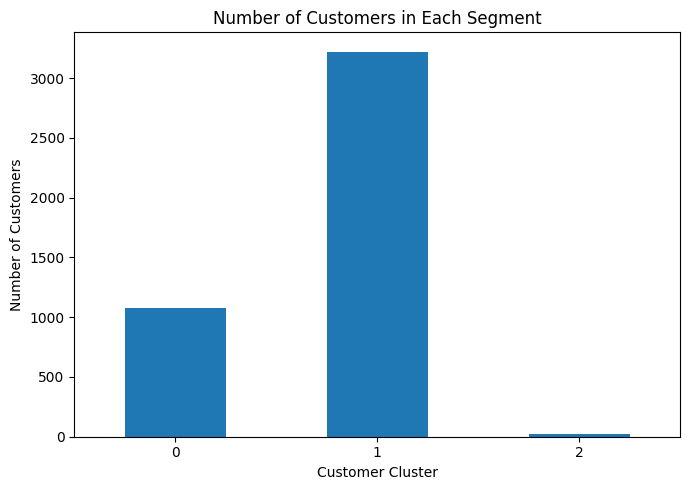

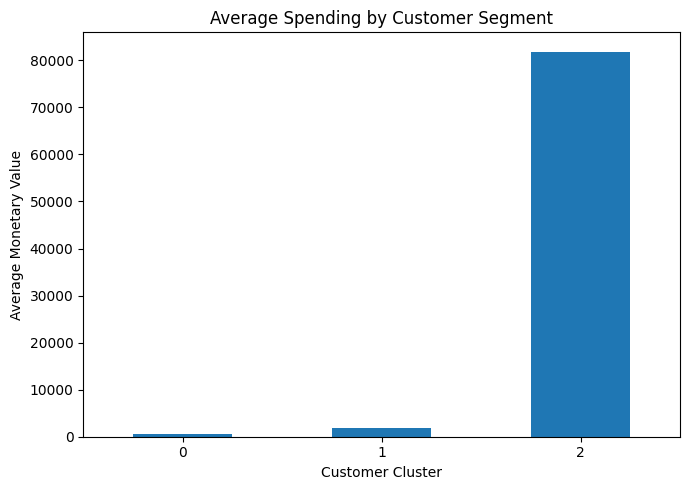

In [11]:

import matplotlib.pyplot as plt

# Graph 1: Number of customers in each cluster
cluster_counts = rfm_model['Cluster'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
cluster_counts.plot(kind='bar')
plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Graph 2: Average spending by cluster
plt.figure(figsize=(7, 5))
cluster_summary['Monetary'].plot(kind='bar')
plt.title('Average Spending by Customer Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Monetary Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Customer Segmentation Analysis Using Python

## Project Overview
This project segments customers based on their purchasing behavior using RFM (Recency, Frequency, Monetary) analysis and the K-Means clustering algorithm.

## Dataset
- Dataset: UCI Online Retail Dataset
- Original records: 541,909
- Original columns: 8
- Unique customers after data cleaning: 4,372
- Customers included in clustering: 4,322

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Project Steps
1. Loaded the Online Retail dataset.
2. Checked missing values, duplicate records, and data types.
3. Removed duplicate records and rows with missing CustomerID or Description.
4. Calculated TotalAmount for each transaction.
5. Performed RFM analysis for each customer.
6. Excluded customers with zero or negative total spending from this clustering.
7. Scaled the RFM features using StandardScaler.
8. Used the Elbow Method to help select the number of clusters.
9. Applied K-Means clustering with 3 clusters.
10. Visualized customer segment sizes and average spending.

## Results
- Cluster 0: 1,077 low-activity customers
- Cluster 1: 3,222 regular customers
- Cluster 2: 23 high-value customers

## Conclusion
The project identified three customer segments with different purchasing patterns. These insights can help businesses understand customer behavior, plan targeted marketing campaigns, and develop customer retention strategies.

The cluster labels are preliminary interpretations based on average RFM values.
